# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

In [1]:
# Preliminares
import pandas as pd

from src.cat_modeling import cargar_datos
from src.transform import categorizar_en_cuantiles
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    pintar_matriz_correlacion, pintar_violin_plots 
)

# Cargar fichero de precios
simbolo = 'SPY'
intervalo = '1d'
df, cols_exclude = cargar_datos(simbolo=simbolo, intervalo=intervalo, leer_cols_exclude=True)
df_clean = df.drop(columns=cols_exclude)
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 5188 entries, 2006-03-16 00:00:00-05:00 to 2026-10-28 00:00:00-04:00
Data columns (total 13 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Close_lag1_sma20_pct_diff_Close_lag1_sma50  5188 non-null   float64
 1   Volume_lag1_pct_diff_Volume_lag1_sma20      5188 non-null   float64
 2   Close_lag1_min20_pct_diff_Open              5188 non-null   float64
 3   High_pct_diff_Open                          5188 non-null   float64
 4   Low_pct_diff_Open                           5188 non-null   float64
 5   Close_pct_diff_Open                         5188 non-null   float64
 6   Low_lag1_pct_diff_Open                      5188 non-null   float64
 7   Close_lag1_pct_diff_Open                    5188 non-null   float64
 8   Close_lag1_sma50_pct_diff_Open              5188 non-null   float64
 9   Daily_return_lag1                    

## Analisis de variables

In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

In [3]:
# Descripcion de variables
df_clean.describe().T

,count,mean,std,min,25%,50%,75%,max
Close_lag1_sma20_pct_diff_Close_lag1_sma50,5188.0,0.006334,0.024617,-0.148874,-0.003604,0.010518,0.020873,0.073720
Volume_lag1_pct_diff_Volume_lag1_sma20,5188.0,0.015645,0.378010,-0.828455,-0.232457,-0.060799,0.165537,3.319121
Close_lag1_min20_pct_diff_Open,5188.0,-0.034587,0.027384,-0.218761,-0.047601,-0.031490,-0.016657,0.076135
High_pct_diff_Open,5188.0,0.005957,0.006941,0.000000,0.001887,0.004070,0.007650,0.111827
Low_pct_diff_Open,5188.0,-0.006464,0.007458,-0.096852,-0.008324,-0.004289,-0.001829,0.000000
Close_pct_diff_Open,5188.0,0.000155,0.009355,-0.089906,-0.003556,0.000574,0.004454,0.111827
Low_lag1_pct_diff_Open,5188.0,-0.006853,0.010082,-0.140879,-0.010197,-0.005465,-0.001843,0.058125
Close_lag1_pct_diff_Open,5188.0,-0.000277,0.007387,-0.057782,-0.003421,-0.000585,0.002370,0.116676
Close_lag1_sma50_pct_diff_Open,5188.0,-0.009131,0.043733,-0.132745,-0.034645,-0.018022,0.004847,0.403588
Daily_return_lag1,5188.0,0.000489,0.012119,-0.109424,-0.003961,0.000693,0.005909,0.145197


In [4]:
# Asimetrias
mostrar_asimetrias(df_clean)

High_pct_diff_Open                            4.243082
Close_lag1_sma50_pct_diff_Open                2.728785
Volume_lag1_pct_diff_Volume_lag1_sma20        1.987572
Close_lag1_pct_diff_Open                      1.720612
Daily_return_lag1_var20_log                   0.653662
Close_lag1_max20_pct_diff_Open_yeo            0.457285
Daily_return_lag1                            -0.001575
Close_pct_diff_Open                          -0.025685
High_lag1_pct_diff_Open_yeo                  -0.506838
Close_lag1_min20_pct_diff_Open               -1.471757
Close_lag1_sma20_pct_diff_Close_lag1_sma50   -1.798210
Low_lag1_pct_diff_Open                       -2.393300
Low_pct_diff_Open                            -3.436882


Cont


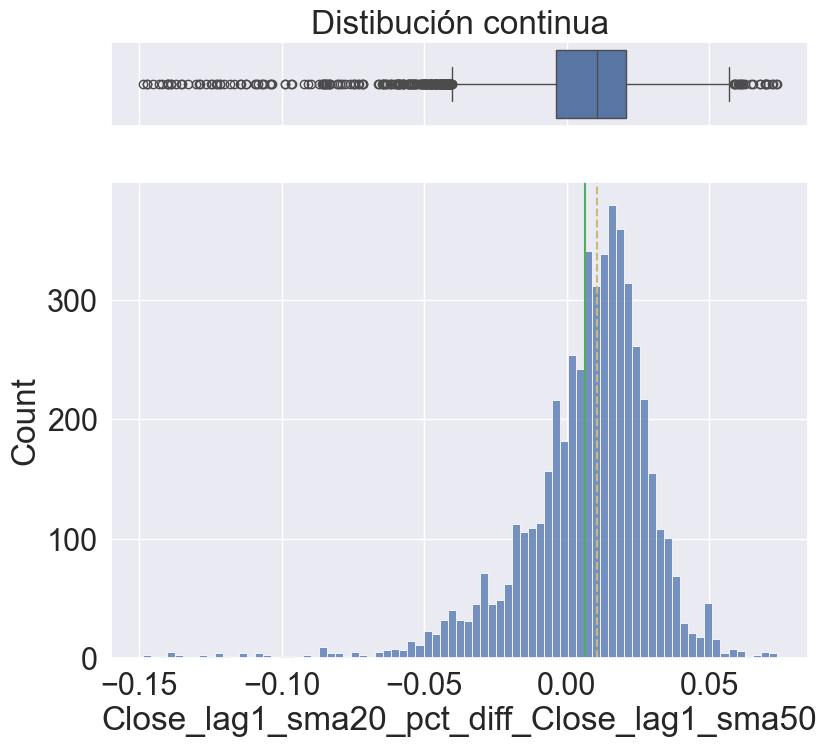

In [5]:
# Visualizar columna
col = 'Close_lag1_sma20_pct_diff_Close_lag1_sma50'
pintar_columna(df_clean[col])

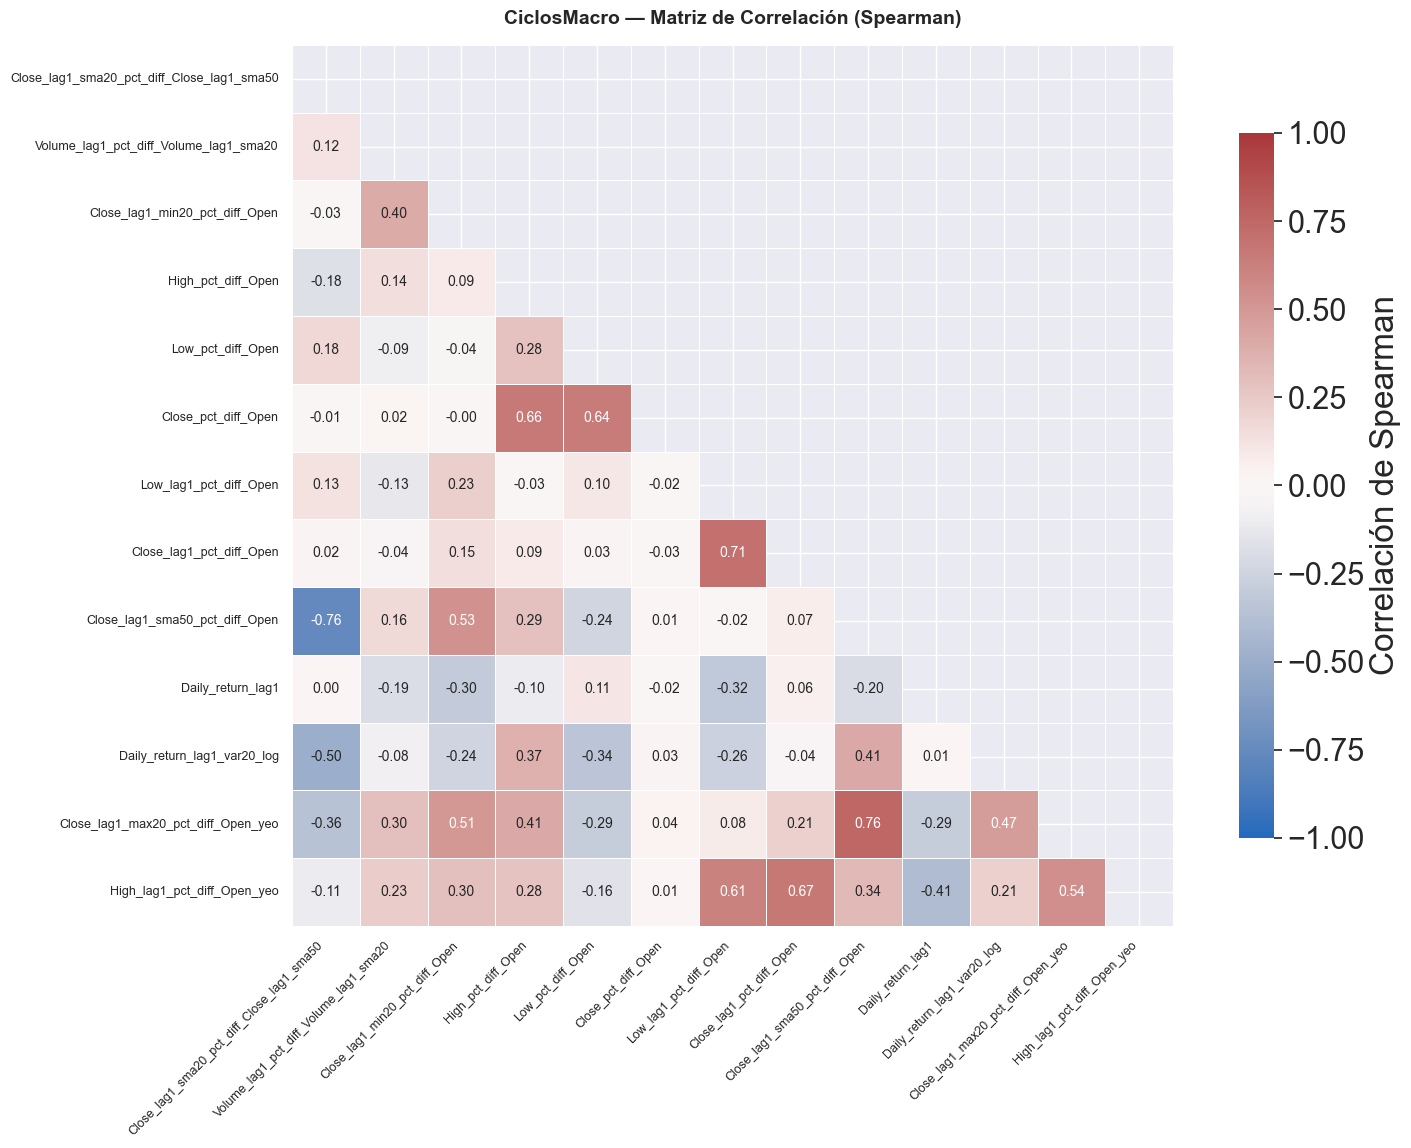

(                                            Close_lag1_sma20_pct_diff_Close_lag1_sma50  \
 Close_lag1_sma20_pct_diff_Close_lag1_sma50                                    1.000000   
 Volume_lag1_pct_diff_Volume_lag1_sma20                                        0.119699   
 Close_lag1_min20_pct_diff_Open                                               -0.029677   
 High_pct_diff_Open                                                           -0.177143   
 Low_pct_diff_Open                                                             0.177785   
 Close_pct_diff_Open                                                          -0.006168   
 Low_lag1_pct_diff_Open                                                        0.131714   
 Close_lag1_pct_diff_Open                                                      0.024656   
 Close_lag1_sma50_pct_diff_Open                                               -0.761306   
 Daily_return_lag1                                                             0.001713   

In [6]:
# Matriz de correlacion
pintar_matriz_correlacion(df_clean)

* `Close_pct_diff_Open` presenta escasa correlacion con los predictores, siendo el posible label mas debil.

## Analisis de labels

In [7]:
posibles_labels = ['High_pct_diff_Open', 'Low_pct_diff_Open', 'Close_pct_diff_Open']

objetivo = 'High_pct_diff_Open'
objetivo_cat = f"{objetivo}_cat"

df_clean, tabla_bins = categorizar_en_cuantiles(
    df_clean, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=False
    )

# Se eliminan las posibles labels continuas
df_clean = df_clean.drop(columns=posibles_labels)

print("\n--- Rangos por Categoría ---")
print(tabla_bins)


--- Rangos por Categoría ---
   categoria  lim_inferior  lim_superior
0          1      0.000000      0.002572
1          2      0.002572      0.006187
2          3      0.006187      0.111827


In [8]:
df_clean[objetivo_cat].value_counts()

High_pct_diff_Open_cat
2    1730
1    1729
3    1729
Name: count, dtype: int64

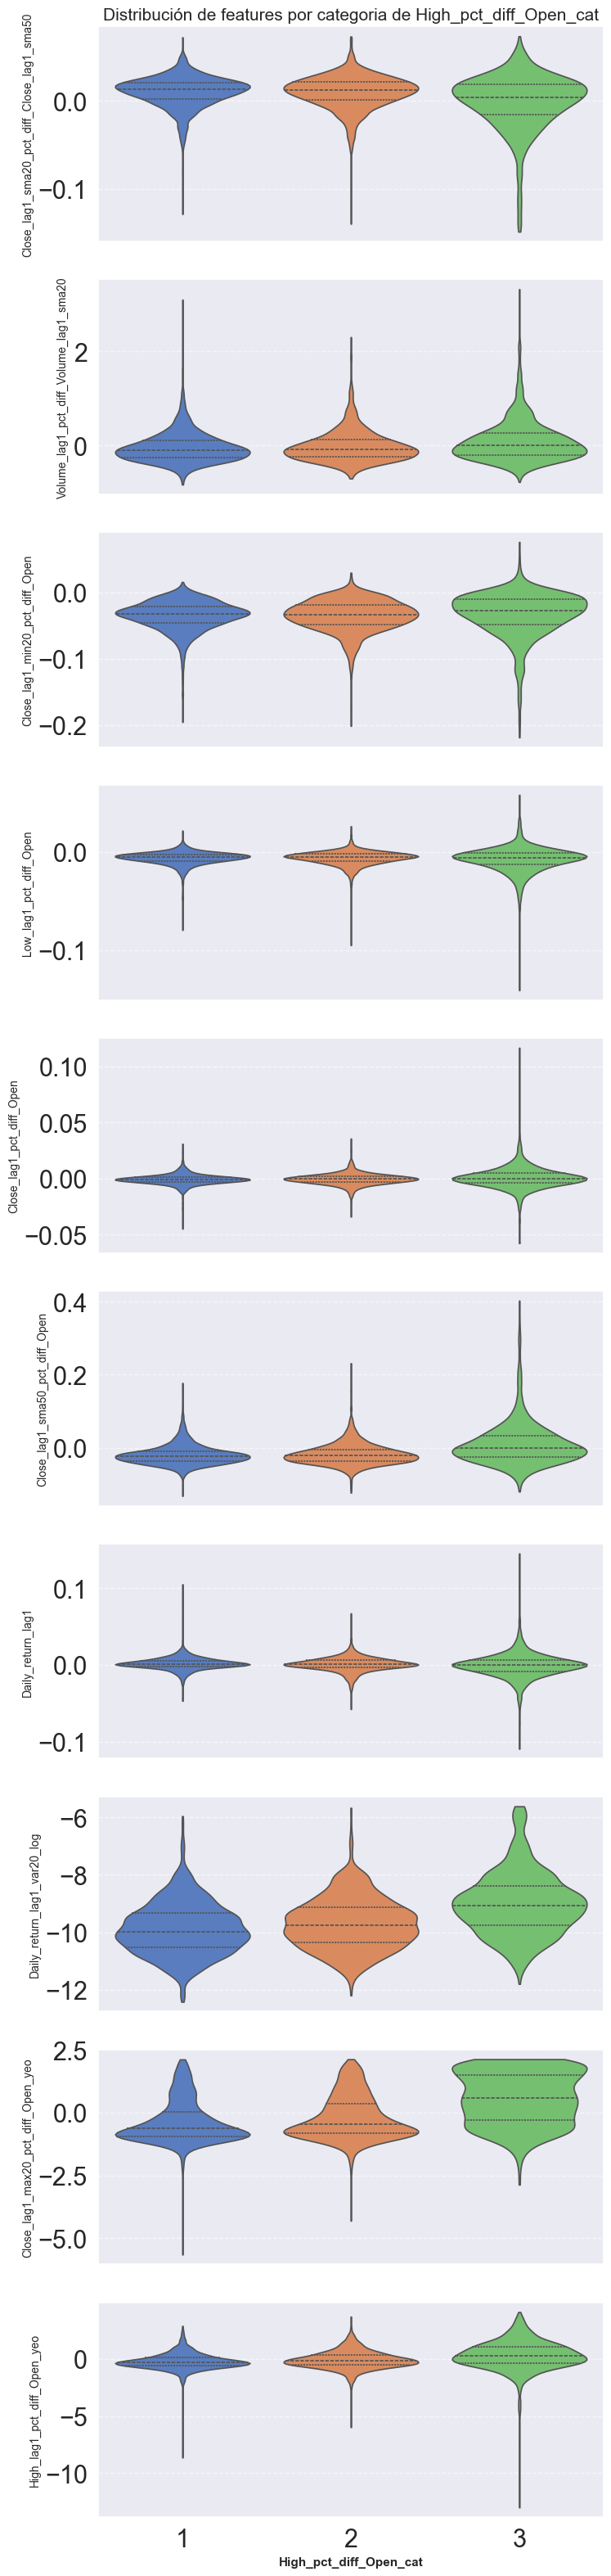

In [9]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_clean.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]

pintar_violin_plots(
    df=df_clean,
    numeric_cols=numeric_cols,
    target_col=target_col
)

In [10]:
# Crear variable binaria: True si pertenece a la clase superior
df_clean['target_col_bin'] = (df_clean[objetivo_cat] ==3).astype(int)
df_clean['target_col_bin'].value_counts()

target_col_bin
0    3459
1    1729
Name: count, dtype: int64

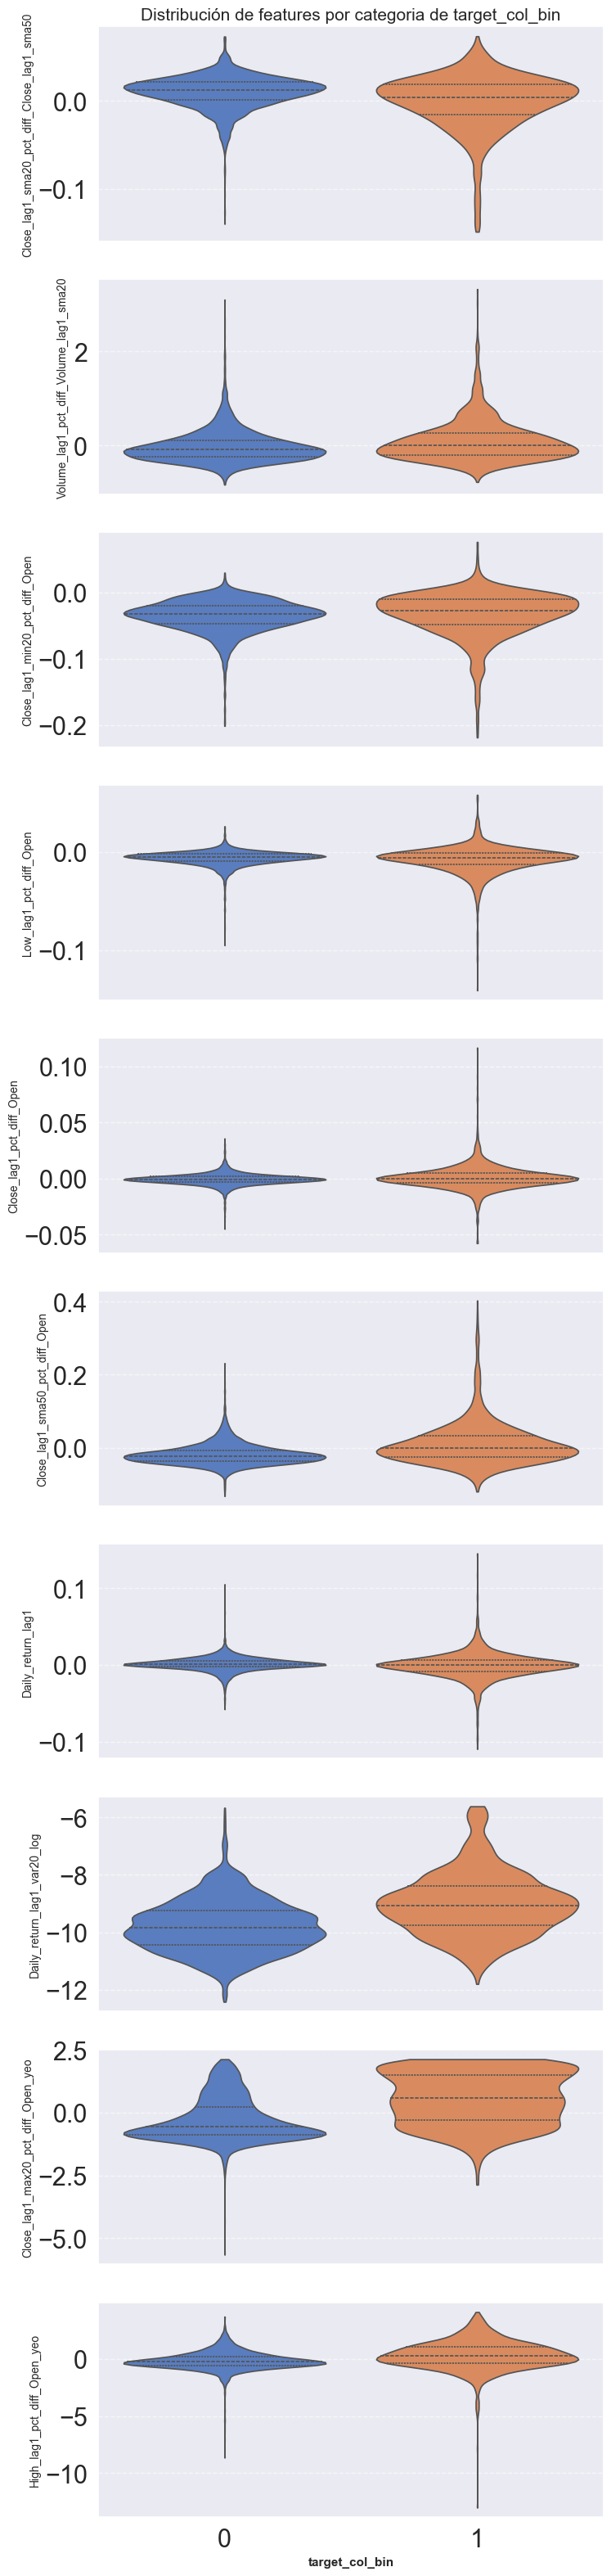

In [11]:
# Se elimina la variable objetivo multiclase
df_clean.drop(columns=[target_col], inplace=True)

# Graficos de violines
pintar_violin_plots(
    df=df_clean,
    numeric_cols=numeric_cols,
    target_col='target_col_bin'
)